# Datasets accelerometer analysis

This notebooks objective is to analyze the accelerometer timeseries of three datasets. WISDM, PAMAP2 and Opportunity.

### Imports and declarations

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from scipy import stats
from skimage.transform import resize

In [37]:
# x_axis = 'gyroX'
# y_axis = 'gyroY'
# z_axis = 'gyroZ'

# x_axis = 'x_maf'
# y_axis = 'y_maf'
# z_axis = 'z_maf'

x_axis = 'x_ema'
y_axis = 'y_ema'
z_axis = 'z_ema'


## Functions

In [38]:
def calculate_recurrence_plot(distance_matrix):
    """
    Converts a distance matrix into a recurrence plot in grayscale (0-255).
    
    Parameters:
    - distance_matrix: 2D numpy array representing pairwise distances.
    
    Returns:
    - recurrence_plot: 2D numpy array with values scaled to grayscale (0-255).
    """
    # Normalize the distance matrix to the range 0–1
    normalized_matrix = (distance_matrix - np.min(distance_matrix)) / (np.max(distance_matrix) - np.min(distance_matrix))
    
    # Scale to grayscale (0–255)
    recurrence_plot = (normalized_matrix * 255).astype(np.uint8)
    
    return recurrence_plot


In [39]:
def calculate_distance_matrix(time_series):
    """
    Calculate the recurrence matrix for a given time series.
    
    Parameters:
    - time_series: np.array or list, the input time series data.
    - threshold: float, the distance threshold for determining recurrence.
    
    Returns:
    - rec_matrix: np.array, the recurrence matrix.
    """
    time_series = np.asarray(time_series)
    n = len(time_series)
    rec_matrix = np.zeros((n, n))
    
    for i in range(n):
        for j in range(n):
            distance = np.abs(time_series[i] - time_series[j])
            rec_matrix[i, j] = distance
    
    return rec_matrix

In [40]:
def plot_recurrence_by_activity(data, dataset_name, axis_name, step, first=100, padding=2.0, filename=None):
    num_keys = len(data)
    num_plots_per_key = 4
    fig, axes = plt.subplots(num_keys, num_plots_per_key, figsize=(20, 20))
    
    # Extracting information from filename for the figure title
    figure_title = f'{dataset_name} - {axis_name}'
    fig.suptitle(figure_title, fontsize=20, fontweight="bold")  # Set the figure title

    for i, (key, value) in enumerate(data.items()):
        start = first

        axes[i, 0].set_ylabel(key.capitalize(), fontsize=20, fontweight='bold', rotation=0, labelpad=40, ha='right', va='center')
        for j in range(num_plots_per_key):
            activity_data = value[start:start + step]
            R = calculate_distance_matrix(activity_data)
            R = calculate_recurrence_plot(R)
            ax = axes[i, j]
            cax = ax.matshow(R, cmap='binary')
            ax.set_xticks([])
            ax.set_yticks([])
            start = start + int(step / 2) 

    plt.tight_layout(pad=padding, rect=[0, 0, 1, 0.96])  # Adjust padding and fit the title

    if filename:
        plt.savefig(filename + ".png")  # Save the figure
        plt.close(fig)  # Close the figure to prevent it from displaying
    else:
        plt.show()  # Show the figure

In [41]:
def create_recurrence_plot_images(data, image_size):
    """
    Transform time series data for x, y, and z axes into a list of 3-channel images.

    Parameters:
    - data: pandas DataFrame containing 'x', 'y', and 'z' columns for time series data.
    - image_size: int, the size of each image (height and width will be equal).

    Returns:
    - images: list of 3-channel images (each image corresponds to a window).
    """
    # Define window size based on image_size
    window_size = image_size
    step_size = window_size  # No overlap for now

    images = []

    for start_idx in range(0, len(data) - window_size + 1, step_size):
        # Extract the window for each axis
        window_data = data.iloc[start_idx:start_idx + window_size]

        # Process each axis to create a channel
        channels = []
        for axis in [x_axis, y_axis, z_axis]:
            # Calculate the distance matrix
            time_series = window_data[axis].values
            distance_matrix = calculate_distance_matrix(time_series)

            # Create the recurrence plot
            recurrence_plot = calculate_recurrence_plot(distance_matrix)

            # Resize to the desired image size
            resized_image = resize(recurrence_plot, (image_size, image_size), anti_aliasing=True, mode='reflect')

            # Scale the resized image back to 0-255 and convert to uint8
            resized_image = (resized_image * 255).astype(np.uint8)

            channels.append(resized_image)

        # Stack the three channels to form a 3-channel image
        three_channel_image = np.stack(channels, axis=-1)
        images.append(three_channel_image)

    return images

In [42]:
def plot_recurrence_image(image):
    """
    Plot a single 3-channel recurrence image as an RGB image.

    Parameters:
    - image: 3D numpy array (image_size x image_size x 3), the recurrence plot image.
    """
    if image.shape[-1] != 3:
        raise ValueError("Input image must have 3 channels.")

    # Plot the RGB image
    plt.figure(figsize=(5, 5))
    plt.imshow(image)
    plt.axis('off')
    plt.title("Recurrence Plot (RGB)", fontsize=14)
    plt.show()

In [43]:
def plot_recurrence_images(data, dataset_name, axis_name, padding=2.0, filename=None, figsize=(20,20), num_plots_per_key=4):
    """
    Plot recurrence images for a dataset, displaying them as RGB images.

    Parameters:
    - data: dictionary with activity names as keys and lists of RGB images as values.
    - dataset_name: str, name of the dataset.
    - axis_name: str, name of the axis being processed.
    - step: int, size of the time window used to generate images.
    - padding: float, padding for layout.
    - filename: str or None, if provided, saves the plot as a file.
    """
    num_keys = len(data)
    fig, axes = plt.subplots(num_keys, num_plots_per_key, figsize=figsize)

    # Extracting information from filename for the figure title
    figure_title = f'{dataset_name} - {axis_name}'
    fig.suptitle(figure_title, fontsize=20, fontweight="bold")  # Set the figure title

    for i, (key, images) in enumerate(data.items()):
        axes[i, 0].set_ylabel(key.capitalize(), fontsize=20, fontweight='bold', rotation=0, labelpad=40, ha='right', va='center')
        for j in range(num_plots_per_key):
            if j < len(images):
                rgb_image = images[j]  # Get the j-th RGB image
                ax = axes[i, j]
                ax.imshow(rgb_image)
                ax.set_xticks([])
                ax.set_yticks([])

    plt.tight_layout(pad=padding, rect=[0, 0, 1, 0.96])  # Adjust padding and fit the title

    if filename:
        plt.savefig(filename + ".png")  # Save the figure
        plt.close(fig)  # Close the figure to prevent it from displaying
    else:
        plt.show()  # Show the figure

## WISDM Dataset

### Dataset Preparation

In [111]:
WISDM_WINDOW_SIZE = 128

In [112]:
# Function to normalize columns
def normalize_group(group):
    group[['x', 'y', 'z']] = (group[['x', 'y', 'z']] - group[['x', 'y', 'z']].mean()) / group[['x', 'y', 'z']].std()
    return group

wisdm = pd.read_csv('../../datasets/WISDM_ar_v1.1_balanced.csv', header=None, sep=',', names=['user', 'activity', 'timestamp', 'x', 'y', 'z'])
wisdm = wisdm.groupby('user').apply(normalize_group)
wisdm = wisdm.rename(columns={
    'x': 'accX',
    'y': 'accY',
    'z': 'accZ'
})
wisdm = wisdm.reset_index(drop=True)
wisdm

C:\Users\tulio\AppData\Local\Temp\ipykernel_7488\2392233564.py:7: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  wisdm = wisdm.groupby('user').apply(normalize_group)


,user,activity,timestamp,accX,accY,accZ
0,1,Walking,4992322339000,-0.091720,1.294345,-0.181997
1,1,Walking,4992422345000,0.390024,0.596599,-0.299797
2,1,Walking,4992722333000,1.040662,0.803481,0.175850
3,1,Walking,4993792341000,0.976051,0.650568,-0.224227
4,1,Walking,4993842298000,1.449861,0.680123,0.549256
...,...,...,...,...,...,...
290359,36,Standing,15049012250000,0.430103,0.422333,-0.155289
290360,36,Standing,15049062268000,0.330533,0.436234,-0.166769
290361,36,Standing,15049112287000,0.212525,0.439709,-0.155289
290362,36,Standing,15049162275000,0.002322,0.307651,-0.254785


In [113]:
wisdm[['x_maf', 'y_maf', 'z_maf']] = wisdm.groupby('user')[['accX', 'accY', 'accZ']].rolling(window=20).mean().reset_index(drop=True)
wisdm[['x_ema', 'y_ema', 'z_ema']] = wisdm.groupby('user')[['accX', 'accY', 'accZ']].ewm(span=30, adjust=False).mean().reset_index(drop=True)

In [114]:
wisdm

,user,activity,timestamp,accX,accY,accZ,x_maf,y_maf,z_maf,x_ema,y_ema,z_ema
0,1,Walking,4992322339000,-0.091720,1.294345,-0.181997,NaN,NaN,NaN,-0.091720,1.294345,-0.181997
1,1,Walking,4992422345000,0.390024,0.596599,-0.299797,NaN,NaN,NaN,-0.060640,1.249329,-0.189597
2,1,Walking,4992722333000,1.040662,0.803481,0.175850,NaN,NaN,NaN,0.010412,1.220565,-0.166020
3,1,Walking,4993792341000,0.976051,0.650568,-0.224227,NaN,NaN,NaN,0.072711,1.183791,-0.169775
4,1,Walking,4993842298000,1.449861,0.680123,0.549256,NaN,NaN,NaN,0.161560,1.151296,-0.123386
...,...,...,...,...,...,...,...,...,...,...,...,...
290359,36,Standing,15049012250000,0.430103,0.422333,-0.155289,0.292365,0.422941,-0.155480,0.291351,0.421061,-0.159292
290360,36,Standing,15049062268000,0.330533,0.436234,-0.166769,0.294762,0.423288,-0.156437,0.293879,0.422040,-0.159774
290361,36,Standing,15049112287000,0.212525,0.439709,-0.155289,0.291627,0.423810,-0.156437,0.288630,0.423180,-0.159485
290362,36,Standing,15049162275000,0.002322,0.307651,-0.254785,0.277614,0.417728,-0.161411,0.270159,0.415727,-0.165633


In [115]:
walking_data = wisdm[(wisdm['activity'] == 'Walking') & (wisdm['user'] == 3)]
standing_data = wisdm[(wisdm['activity'] == 'Standing') & (wisdm['user'] == 3)]
sitting_data = wisdm[(wisdm['activity'] == 'Sitting') & (wisdm['user'] == 3)]
jogging_data = wisdm[(wisdm['activity'] == 'Jogging') & (wisdm['user'] == 3)]
upstairs_data = wisdm[(wisdm['activity'] == 'Upstairs') & (wisdm['user'] == 3)]
downstairs_data = wisdm[(wisdm['activity'] == 'Downstairs') & (wisdm['user'] == 3)]

### Recurrence plot - Axis

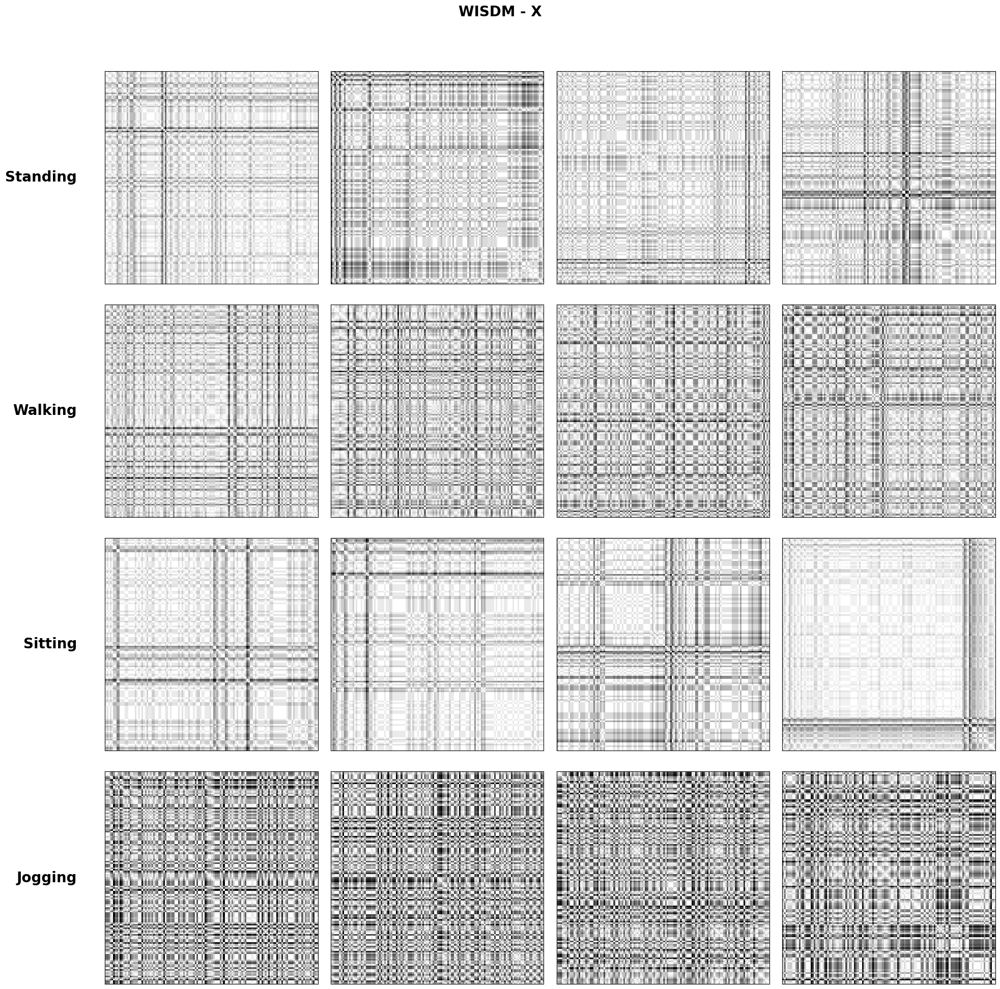

In [116]:
data = {"Standing": standing_data[x_axis].to_numpy(), "Walking": walking_data[x_axis].to_numpy(), "Sitting": sitting_data[x_axis].to_numpy(), "Jogging": jogging_data[x_axis].to_numpy()}

plot_recurrence_by_activity(data, "WISDM", "X", step=WISDM_WINDOW_SIZE, first=200)

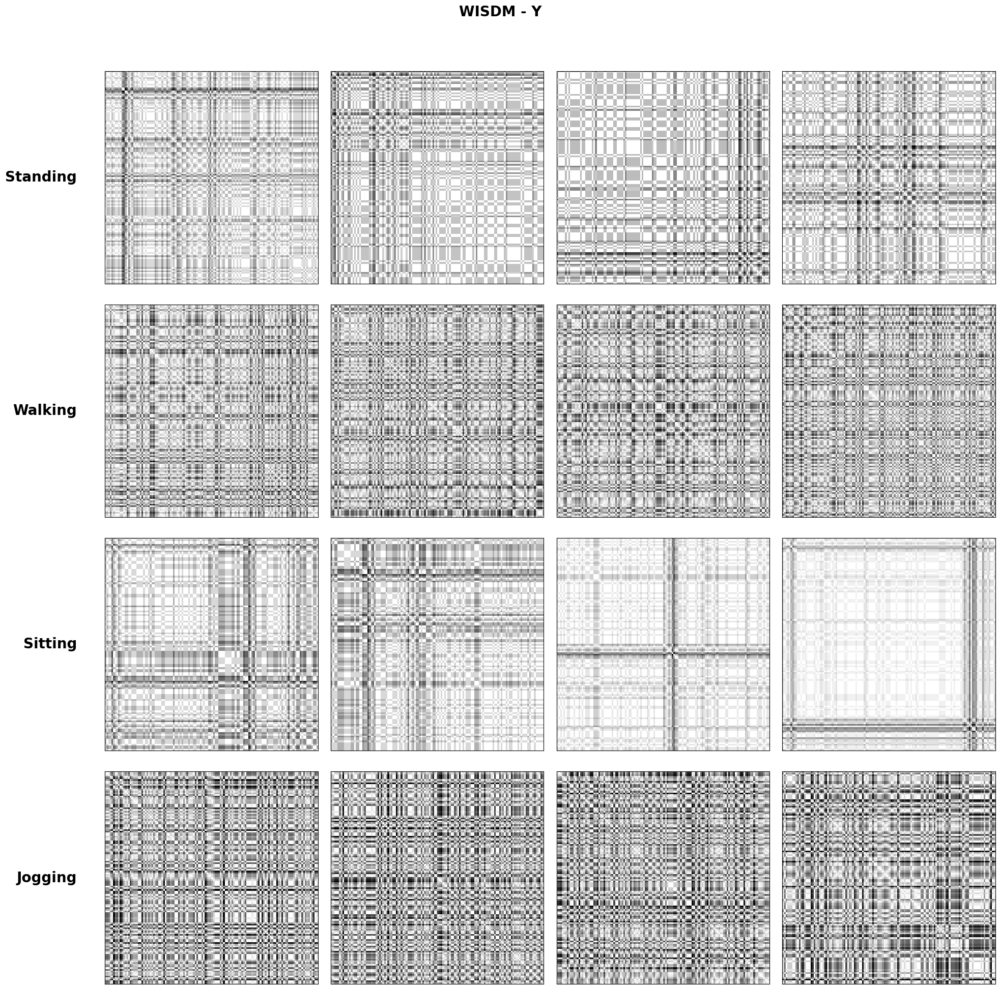

In [117]:
data = {"Standing": standing_data[y_axis].to_numpy(), "Walking": walking_data[y_axis].to_numpy(), "Sitting": sitting_data[y_axis].to_numpy(), "Jogging": jogging_data[x_axis].to_numpy()}

plot_recurrence_by_activity(data, "WISDM", "Y", step=WISDM_WINDOW_SIZE, first=200)

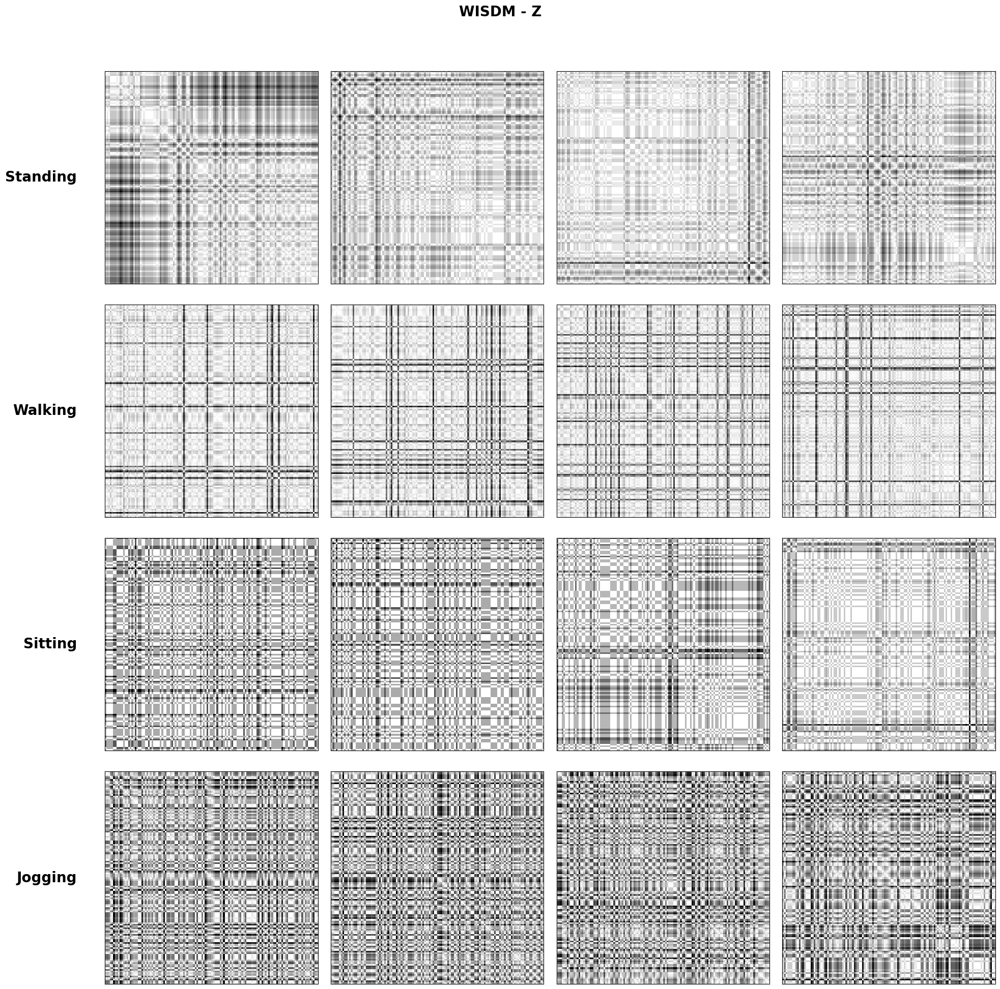

In [118]:
data = {"Standing": standing_data[z_axis].to_numpy(), "Walking": walking_data[z_axis].to_numpy(), "Sitting": sitting_data[z_axis].to_numpy(), "Jogging": jogging_data[x_axis].to_numpy()}

plot_recurrence_by_activity(data, "WISDM", "Z", step=WISDM_WINDOW_SIZE, first=200)

### Recurrence Plots RGB

In [119]:
walking_images = create_recurrence_plot_images(walking_data, WISDM_WINDOW_SIZE)
standing_images = create_recurrence_plot_images(standing_data, WISDM_WINDOW_SIZE)
sitting_images = create_recurrence_plot_images(sitting_data, WISDM_WINDOW_SIZE)
jogging_images = create_recurrence_plot_images(jogging_data, WISDM_WINDOW_SIZE)
upstairs_images = create_recurrence_plot_images(upstairs_data, WISDM_WINDOW_SIZE)
downstairs_images = create_recurrence_plot_images(downstairs_data, WISDM_WINDOW_SIZE)

In [120]:
walking_images[0].shape

(128, 128, 3)

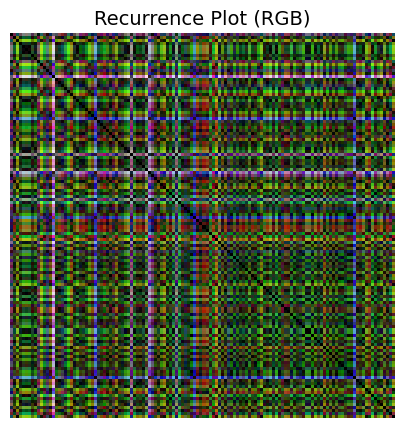

In [121]:
plot_recurrence_image(walking_images[3])

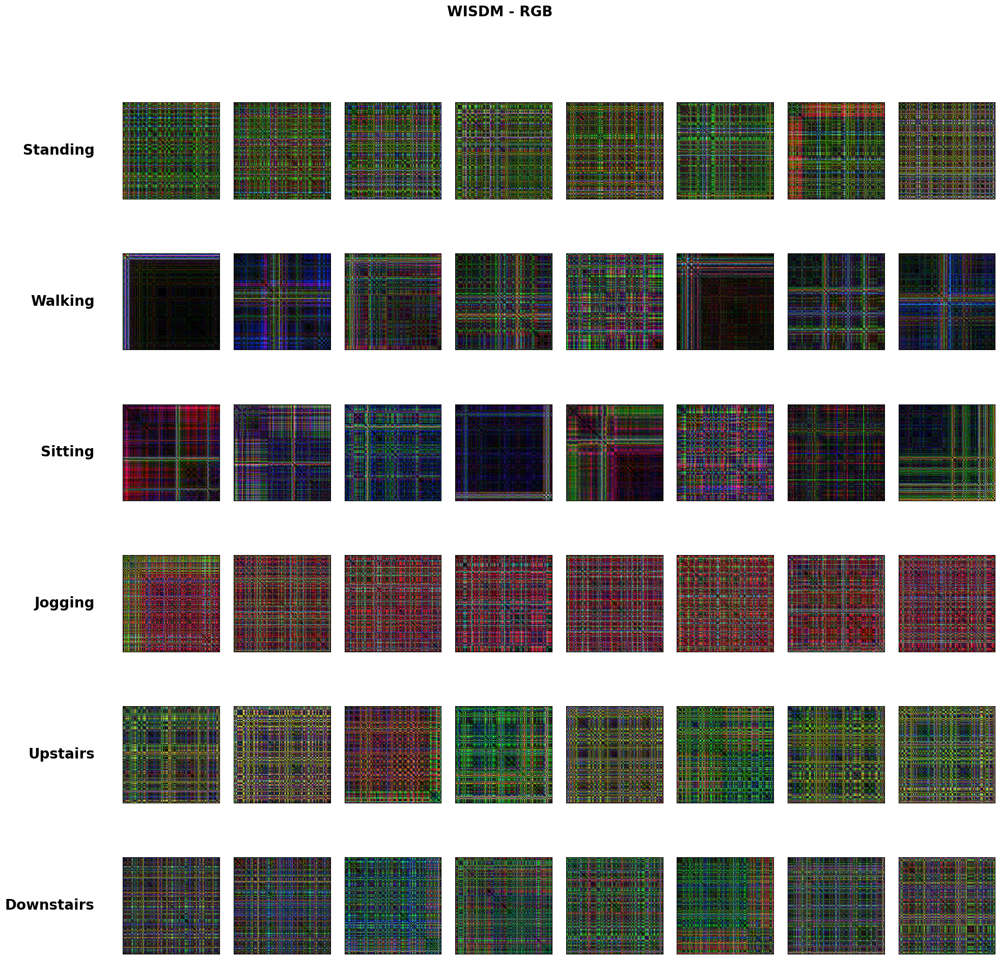

In [122]:
data = {
    "Standing": walking_images, 
    "Walking": standing_images, 
    "Sitting": sitting_images, 
    "Jogging": jogging_images,
    "Upstairs": upstairs_images,
    "Downstairs": downstairs_images
}

plot_recurrence_images(data, "WISDM", "RGB", num_plots_per_key=8)

## PAMAP2 Dataset

### Dataset Preparation

In [44]:
PAMAP_WINDOW_SIZE = 256

In [45]:
# Function to normalize columns
def normalize_group(group):
    group[['hand_gyro_x', 'hand_gyro_y', 'hand_gyro_z']] = (group[['hand_gyro_x', 'hand_gyro_y', 'hand_gyro_z']] - group[['hand_gyro_x', 'hand_gyro_y', 'hand_gyro_z']].mean()) / group[['hand_gyro_x', 'hand_gyro_y', 'hand_gyro_z']].std()
    return group

pamap2 = pd.read_csv('../../datasets/pamap_balanced.csv')
pamap2 = pamap2.groupby('subject_id').apply(normalize_group)
pamap2 = pamap2.rename(columns={
    'hand_gyro_x': 'gyroX',
    'hand_gyro_y': 'gyroY',
    'hand_gyro_z': 'gyroZ'
})
pamap2 = pamap2.reset_index(drop=True)
pamap2

C:\Users\tulio\AppData\Local\Temp\ipykernel_18336\1926684104.py:7: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  pamap2 = pamap2.groupby('subject_id').apply(normalize_group)


,timestamp,activity_id,hand_acc_16g_x,hand_acc_16g_y,hand_acc_16g_z,hand_acc_6g_x,hand_acc_6g_y,hand_acc_6g_z,gyroX,gyroY,gyroZ,hand_mag_x,hand_mag_y,hand_mag_z,subject_id
0,309.53,2,2.124620,9.24108,2.77335,2.424750,9.12390,3.02166,-0.025334,-0.060346,-0.007292,15.0033,-67.00450,-1.055520,1
1,309.54,2,2.338250,9.27392,2.39156,2.394240,9.13917,2.96125,-0.023470,-0.073357,0.003876,14.5708,-66.98840,-0.356026,1
2,309.55,2,2.227290,9.23752,2.46700,2.378790,9.21468,2.84029,-0.043238,-0.100840,-0.003243,14.6740,-67.31640,-0.707928,1
3,309.56,2,2.190040,9.12433,2.50531,2.377660,9.13912,2.78006,-0.100765,-0.077383,0.002216,14.7736,-67.42350,-1.288870,1
4,309.57,2,2.391820,9.23971,2.85433,2.361820,9.04862,2.78027,-0.099337,-0.084452,0.005050,15.1053,-66.56780,-1.630630,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
926023,3630.07,5,0.489770,2.82383,9.23639,0.374732,2.89221,9.30422,0.078310,-0.080624,0.035942,17.7034,-4.55562,-41.179600,8
926024,3630.08,5,0.370253,2.70955,9.08103,0.526067,2.89119,9.37958,0.068326,-0.124859,0.037895,17.9510,-4.56875,-41.048800,8
926025,3630.09,5,0.644139,2.70986,9.35454,0.630675,2.81489,9.34943,0.086694,-0.087619,0.051403,17.9572,-4.94146,-41.177700,8
926026,3630.10,5,0.566153,2.74771,9.27627,0.720712,2.70858,9.40998,0.074588,-0.047181,0.056104,17.7079,-4.80414,-41.309300,8


In [46]:
pamap2[['x_maf', 'y_maf', 'z_maf']] = pamap2.groupby('subject_id')[['gyroX', 'gyroY', 'gyroZ']].rolling(window=100).mean().reset_index(drop=True)
pamap2[['x_ema', 'y_ema', 'z_ema']] = pamap2.groupby('subject_id')[['gyroX', 'gyroY', 'gyroZ']].ewm(span=150, adjust=False).mean().reset_index(drop=True)

In [47]:
walking_data = pamap2[(pamap2['activity_id'] == 4) & (pamap2['subject_id'] == 5)]
standing_data = pamap2[(pamap2['activity_id'] == 3) & (pamap2['subject_id'] == 5)]
sitting_data = pamap2[(pamap2['activity_id'] == 2) & (pamap2['subject_id'] == 5)]
jogging_data = pamap2[(pamap2['activity_id'] == 5) & (pamap2['subject_id'] == 5)]

### Recurrence plot - Axis

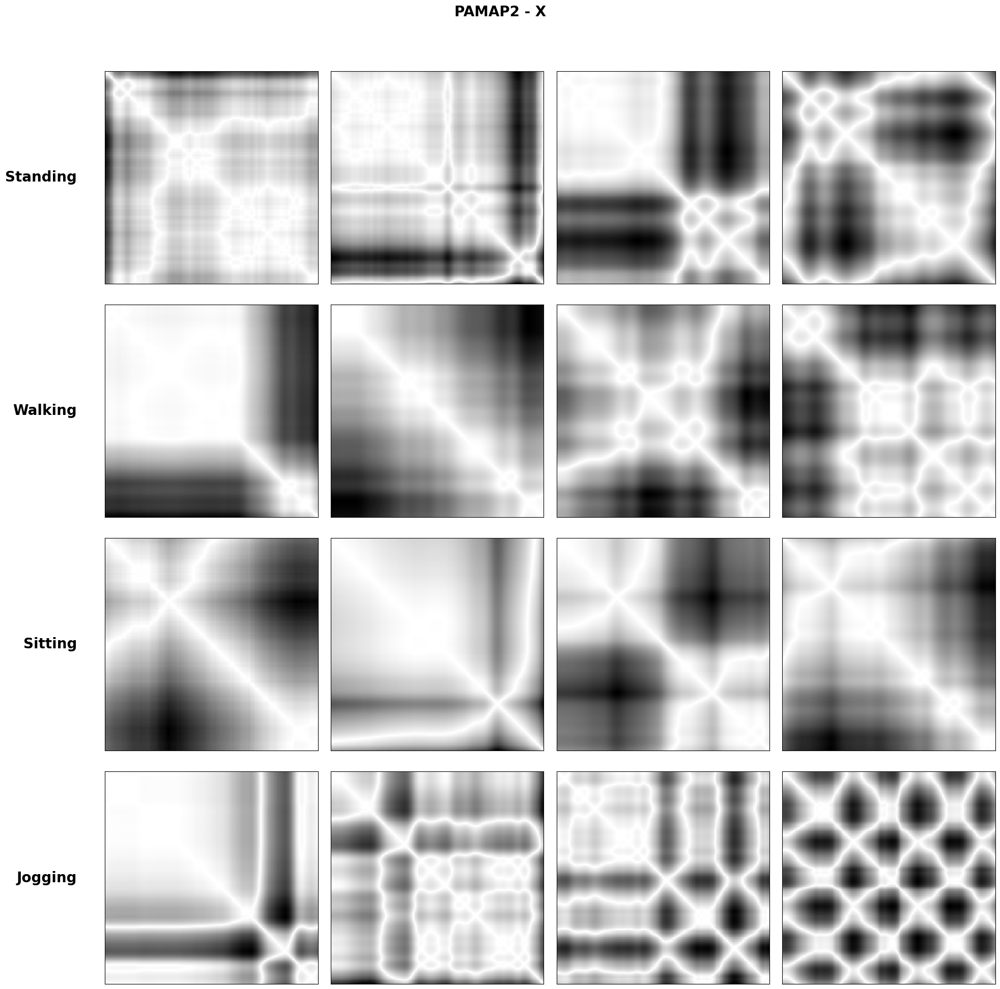

In [48]:
data = {"Standing": standing_data[x_axis].to_numpy(), "Walking": walking_data[x_axis].to_numpy(), "Sitting": sitting_data[x_axis].to_numpy(), "Jogging": jogging_data[x_axis].to_numpy()}

plot_recurrence_by_activity(data, "PAMAP2", "X", step=PAMAP_WINDOW_SIZE, first=200)

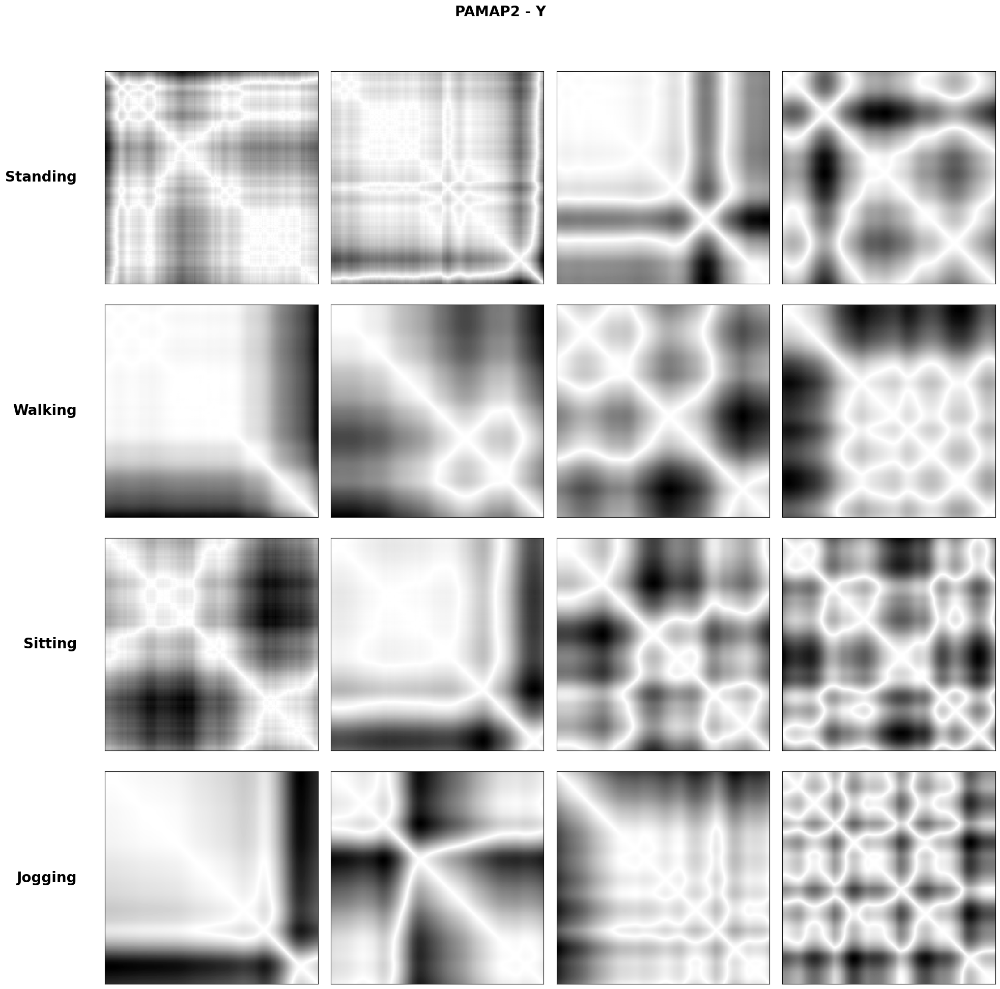

In [49]:
data = {"Standing": standing_data[y_axis].to_numpy(), "Walking": walking_data[y_axis].to_numpy(), "Sitting": sitting_data[y_axis].to_numpy(), "Jogging": jogging_data[y_axis].to_numpy()}

plot_recurrence_by_activity(data, "PAMAP2", "Y", step=PAMAP_WINDOW_SIZE, first=200)

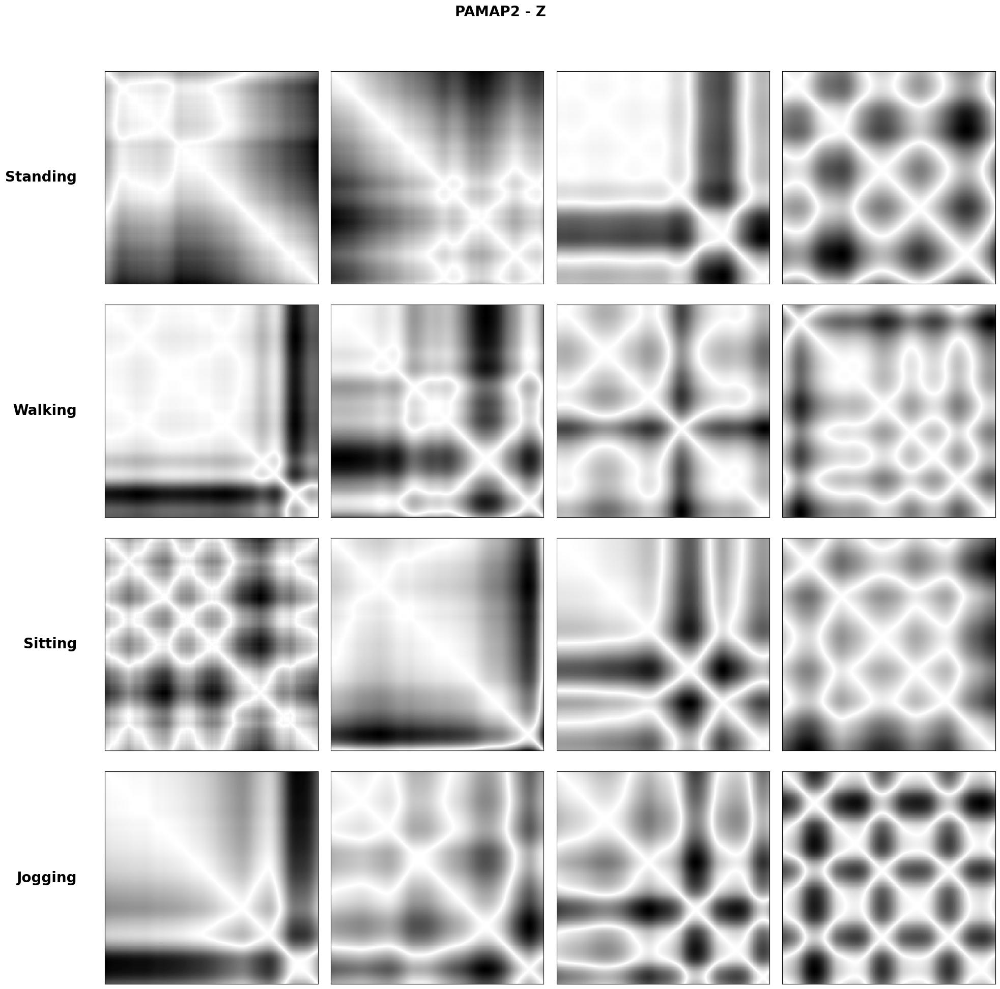

In [50]:
data = {"Standing": standing_data[z_axis].to_numpy(), "Walking": walking_data[z_axis].to_numpy(), "Sitting": sitting_data[z_axis].to_numpy(), "Jogging": jogging_data[z_axis].to_numpy()}

plot_recurrence_by_activity(data, "PAMAP2", "Z", step=PAMAP_WINDOW_SIZE, first=200)

### Recurrence Plots RGB

In [51]:
walking_images = create_recurrence_plot_images(walking_data, PAMAP_WINDOW_SIZE)
standing_images = create_recurrence_plot_images(standing_data, PAMAP_WINDOW_SIZE)
sitting_images = create_recurrence_plot_images(sitting_data, PAMAP_WINDOW_SIZE)
jogging_images = create_recurrence_plot_images(jogging_data, PAMAP_WINDOW_SIZE)

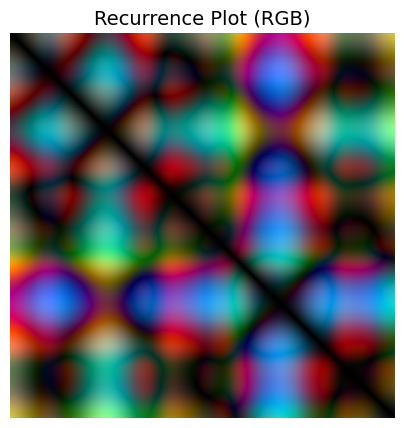

In [52]:
plot_recurrence_image(walking_images[3])

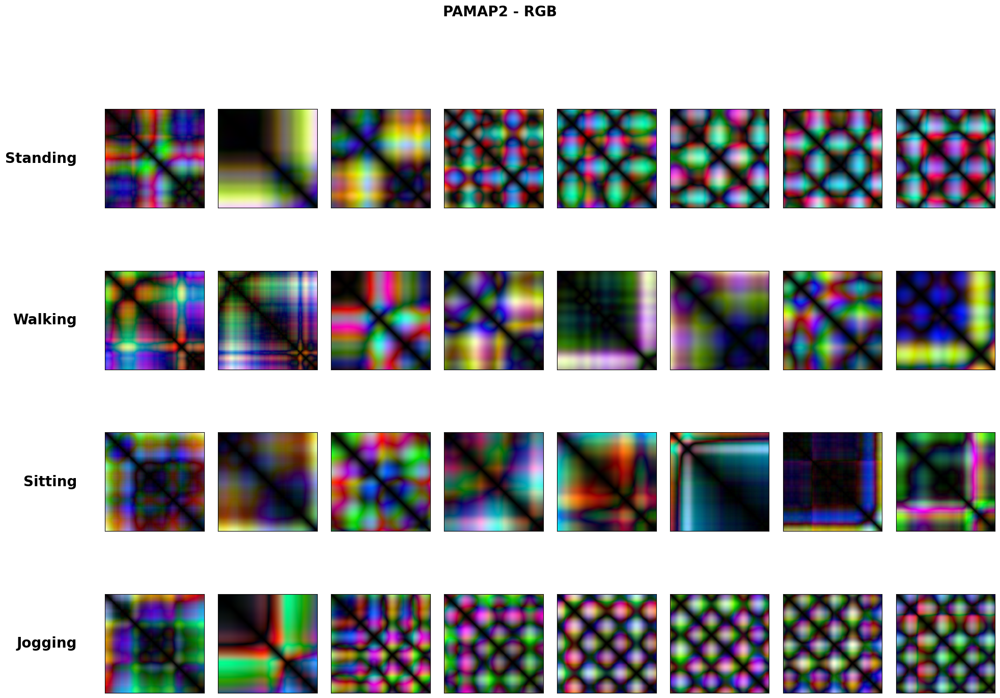

In [53]:
data = {
    "Standing": walking_images, 
    "Walking": standing_images, 
    "Sitting": sitting_images, 
    "Jogging": jogging_images
}

plot_recurrence_images(data, "PAMAP2", "RGB", num_plots_per_key=8, figsize=(20, 15))

## Opportunity 

### Dataset Preparation

In [ ]:
PAMAP_WINDOW_SIZE = 256

In [ ]:
# Function to normalize columns
def normalize_group(group):
    group[['hand_acc_16g_x', 'hand_acc_16g_y', 'hand_acc_16g_z']] = (group[['hand_acc_16g_x', 'hand_acc_16g_y', 'hand_acc_16g_z']] - group[['hand_acc_16g_x', 'hand_acc_16g_y', 'hand_acc_16g_z']].mean()) / group[['hand_acc_16g_x', 'hand_acc_16g_y', 'hand_acc_16g_z']].std()
    return group

pamap2 = pd.read_csv('../../datasets/pamap_balanced.csv')
pamap2 = pamap2.groupby('subject_id').apply(normalize_group)
pamap2 = pamap2.rename(columns={
    'hand_acc_16g_x': 'accX',
    'hand_acc_16g_y': 'accY',
    'hand_acc_16g_z': 'accZ'
})
pamap2 = pamap2.reset_index(drop=True)
pamap2

C:\Users\tulio\AppData\Local\Temp\ipykernel_7488\3292868794.py:7: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  pamap2 = pamap2.groupby('subject_id').apply(normalize_group)


,timestamp,activity_id,accX,accY,accZ,hand_acc_6g_x,hand_acc_6g_y,hand_acc_6g_z,hand_gyro_x,hand_gyro_y,hand_gyro_z,hand_mag_x,hand_mag_y,hand_mag_z,subject_id
0,309.53,2,1.173981,0.391292,0.007209,2.424750,9.12390,3.02166,0.037944,0.024816,-0.016013,15.0033,-67.00450,-1.055520,1
1,309.54,2,1.205812,0.395961,-0.151766,2.394240,9.13917,2.96125,0.040065,0.011347,0.009483,14.5708,-66.98840,-0.356026,1
2,309.55,2,1.189279,0.390786,-0.120353,2.378790,9.21468,2.84029,0.017566,-0.017100,-0.006770,14.6740,-67.31640,-0.707928,1
3,309.56,2,1.183728,0.374697,-0.104401,2.377660,9.13912,2.78006,-0.047912,0.007181,0.005693,14.7736,-67.42350,-1.288870,1
4,309.57,2,1.213794,0.391098,0.040929,2.361820,9.04862,2.78027,-0.046287,-0.000137,0.012163,15.1053,-66.56780,-1.630630,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
926023,3630.07,5,1.268499,0.884639,2.541252,0.374732,2.89221,9.30422,-0.017195,0.006944,0.007758,17.7034,-4.55562,-41.179600,8
926024,3630.08,5,1.250323,0.870380,2.488375,0.526067,2.89119,9.37958,-0.032333,-0.044224,0.011758,17.9510,-4.56875,-41.048800,8
926025,3630.09,5,1.291976,0.870418,2.581465,0.630675,2.81489,9.34943,-0.004483,-0.001148,0.039415,17.9572,-4.94146,-41.177700,8
926026,3630.10,5,1.280116,0.875141,2.554826,0.720712,2.70858,9.40998,-0.022839,0.045628,0.049042,17.7079,-4.80414,-41.309300,8


In [ ]:
pamap2[['x_maf', 'y_maf', 'z_maf']] = pamap2.groupby('subject_id')[['accX', 'accY', 'accZ']].rolling(window=100).mean().reset_index(drop=True)
pamap2[['x_ema', 'y_ema', 'z_ema']] = pamap2.groupby('subject_id')[['accX', 'accY', 'accZ']].ewm(span=150, adjust=False).mean().reset_index(drop=True)

In [ ]:
walking_data = pamap2[(pamap2['activity_id'] == 4) & (pamap2['subject_id'] == 5)]
standing_data = pamap2[(pamap2['activity_id'] == 3) & (pamap2['subject_id'] == 5)]
sitting_data = pamap2[(pamap2['activity_id'] == 2) & (pamap2['subject_id'] == 5)]
jogging_data = pamap2[(pamap2['activity_id'] == 5) & (pamap2['subject_id'] == 5)]

In [133]:
OPPORTUNITY_WINDOW_SIZE = 64

In [134]:
# Function to normalize columns
def normalize_group(group):
    group[['accX', 'accY', 'accZ']] = (group[['accX', 'accY', 'accZ']] - group[['accX', 'accY', 'accZ']].mean()) / group[['accX', 'accY', 'accZ']].std()
    return group

opportunity = pd.read_csv('../../datasets/opportunity_preprocessed.csv')
opportunity = opportunity.dropna()
opportunity = opportunity.groupby('user_id').apply(normalize_group)
pamap2 = pamap2.rename(columns={
    'accX': 'accX',
    'accY': 'accY',
    'accZ': 'accZ'
})
opportunity = opportunity.reset_index(drop=True)
opportunity

C:\Users\tulio\AppData\Local\Temp\ipykernel_7488\2026013340.py:8: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  opportunity = opportunity.groupby('user_id').apply(normalize_group)


,timestamp,accX,accY,accZ,gyroX,gyroY,gyroZ,magneticX,magneticY,magneticZ,activity,user_id
0,0,-0.568511,0.505695,0.480930,-145.0,47.0,48.0,389.0,202.0,593.0,0,1
1,33,-0.611531,0.509278,0.447956,-318.0,-6.0,23.0,390.0,196.0,597.0,0,1
2,67,-0.584155,0.509278,0.388601,-426.0,13.0,49.0,392.0,192.0,598.0,0,1
3,100,-0.523537,0.437617,0.385304,-348.0,46.0,54.0,390.0,187.0,601.0,0,1
4,133,-0.484428,0.362373,0.421576,-329.0,76.0,100.0,389.0,179.0,605.0,0,1
...,...,...,...,...,...,...,...,...,...,...,...,...
854319,1008123,-0.837009,0.444280,-0.103575,222.0,858.0,-67.0,145.0,721.0,-92.0,0,5
854320,1008157,-0.805397,0.645619,0.100670,467.0,710.0,-110.0,142.0,720.0,-101.0,0,5
854321,1008190,-0.708804,0.648919,0.193509,436.0,392.0,-185.0,139.0,721.0,-111.0,0,5
854322,1008223,-0.733391,0.738036,0.119238,145.0,149.0,-121.0,136.0,720.0,-120.0,0,5


In [135]:
opportunity[['x_maf', 'y_maf', 'z_maf']] = opportunity.groupby('user_id')[['accX', 'accY', 'accZ']].rolling(window=30).mean().reset_index(drop=True)
opportunity[['x_ema', 'y_ema', 'z_ema']] = opportunity.groupby('user_id')[['accX', 'accY', 'accZ']].ewm(span=45, adjust=False).mean().reset_index(drop=True)

In [136]:
walking_data = opportunity[(opportunity['activity'] == 2) & (opportunity['user_id'] == 1)]
standing_data = opportunity[(opportunity['activity'] == 1) & (opportunity['user_id'] == 1)]
sitting_data = opportunity[(opportunity['activity'] == 4) & (opportunity['user_id'] == 1)]

### Recurrence plot - Axis

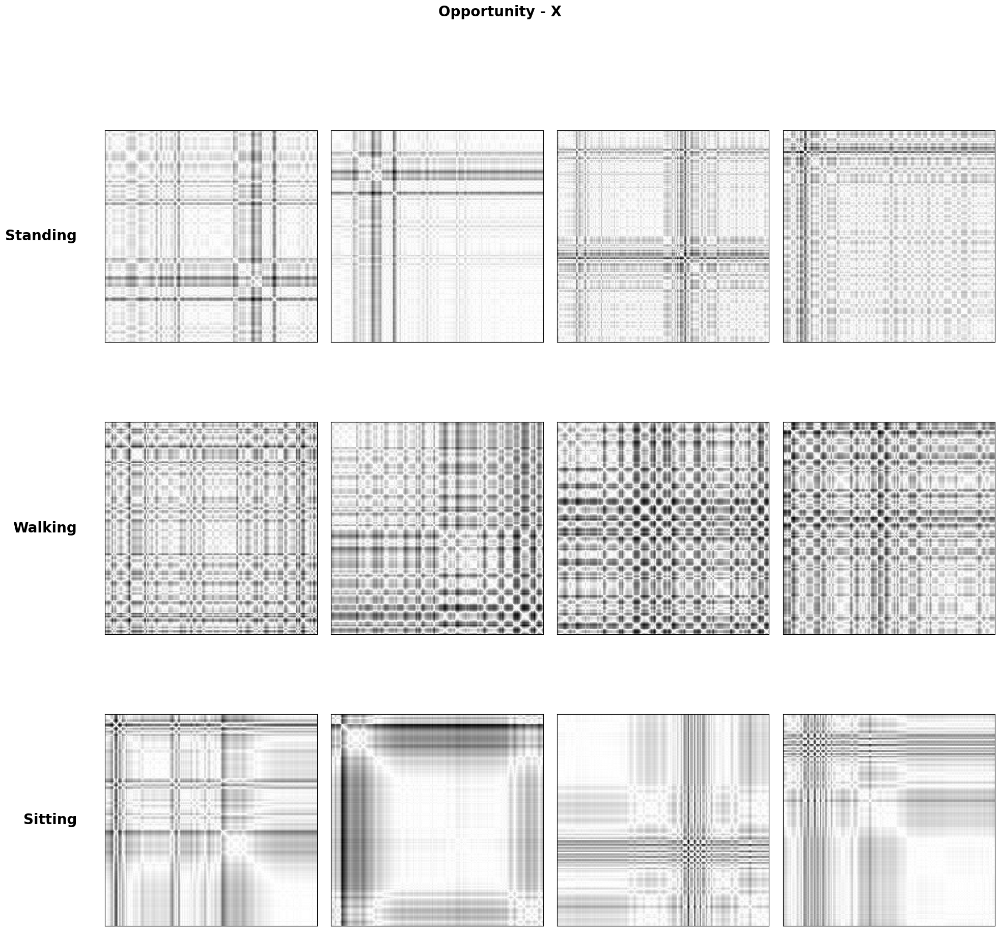

In [137]:
data = {"Standing": standing_data[x_axis].to_numpy(), "Walking": walking_data[x_axis].to_numpy(), "Sitting": sitting_data[x_axis].to_numpy()}

plot_recurrence_by_activity(data, "Opportunity", "X", step=PAMAP_WINDOW_SIZE, first=200)

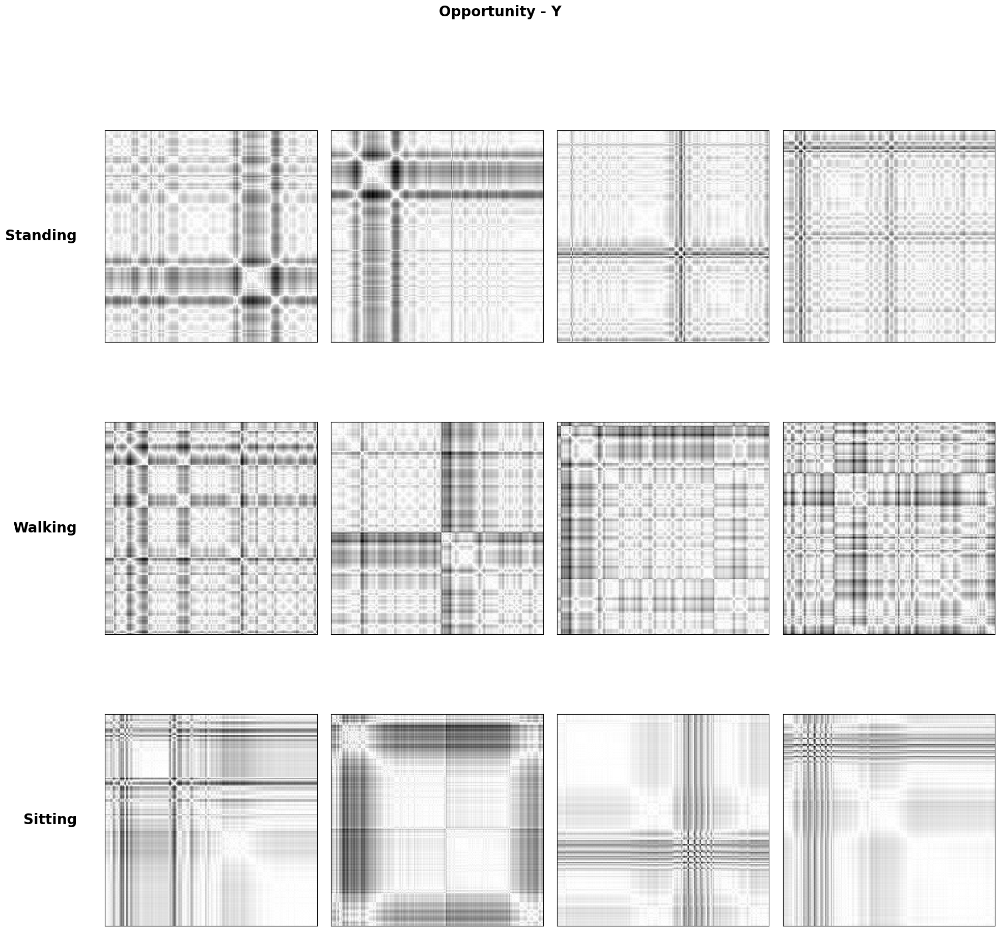

In [138]:
data = {"Standing": standing_data[y_axis].to_numpy(), "Walking": walking_data[y_axis].to_numpy(), "Sitting": sitting_data[y_axis].to_numpy()}

plot_recurrence_by_activity(data, "Opportunity", "Y", step=PAMAP_WINDOW_SIZE, first=200)

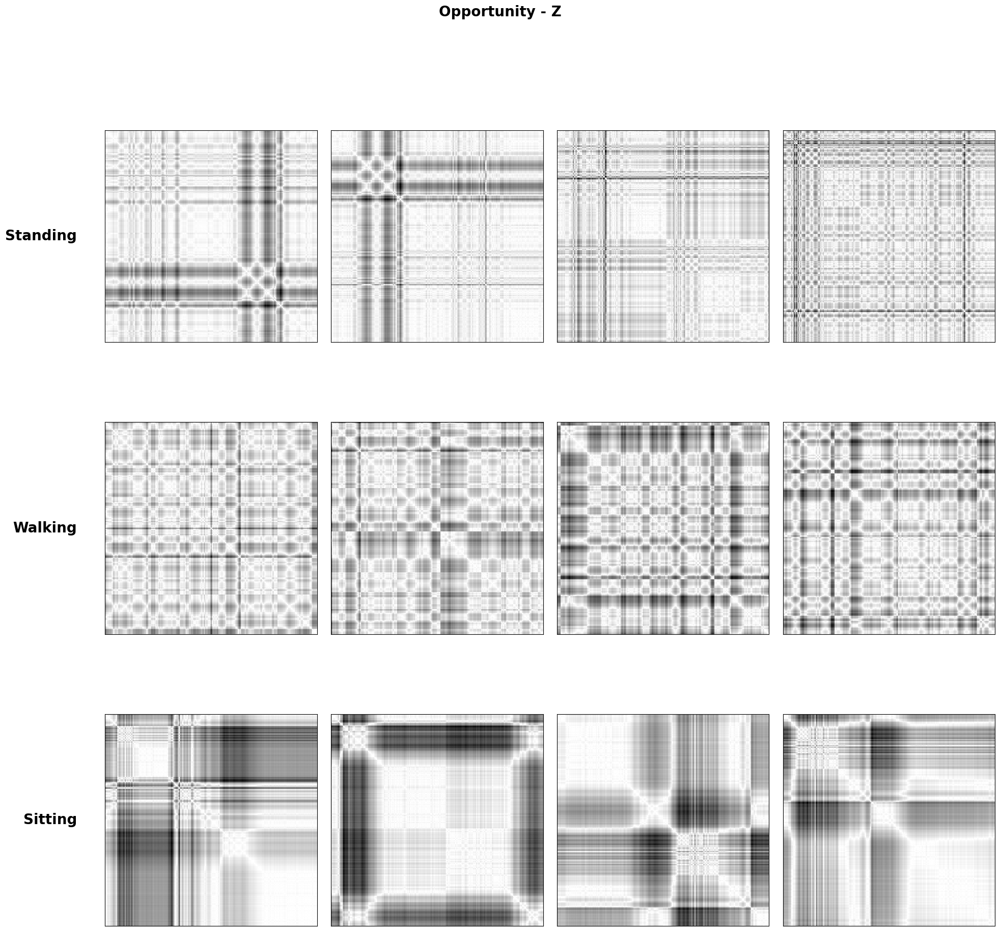

In [139]:
data = {"Standing": standing_data[z_axis].to_numpy(), "Walking": walking_data[z_axis].to_numpy(), "Sitting": sitting_data[z_axis].to_numpy()}

plot_recurrence_by_activity(data, "Opportunity", "Z", step=PAMAP_WINDOW_SIZE, first=200)

### Recurrence Plots RGB

In [140]:
walking_images = create_recurrence_plot_images(walking_data, OPPORTUNITY_WINDOW_SIZE)
standing_images = create_recurrence_plot_images(standing_data, OPPORTUNITY_WINDOW_SIZE)
sitting_images = create_recurrence_plot_images(sitting_data, OPPORTUNITY_WINDOW_SIZE)

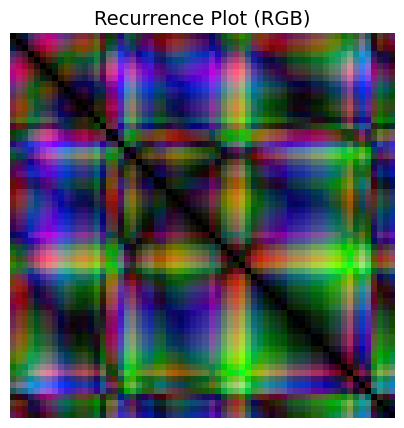

In [141]:
plot_recurrence_image(walking_images[3])

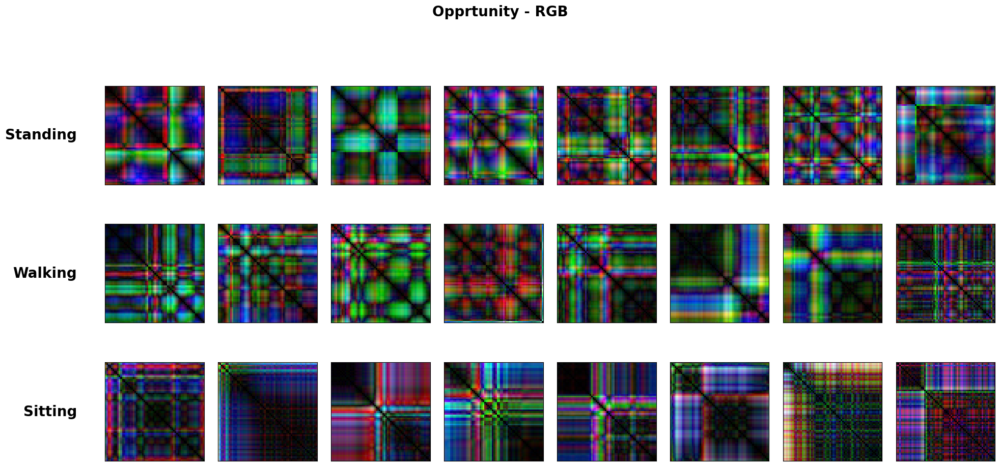

In [142]:
data = {
    "Standing": walking_images, 
    "Walking": standing_images, 
    "Sitting": sitting_images
}

plot_recurrence_images(data, "Opprtunity", "RGB", num_plots_per_key=8, figsize=(20, 10))